# GSE49454 — SLE Disease Context Analysis


In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.stats import mannwhitneyu, gaussian_kde, zscore, ks_2samp
from scipy.signal import argrelmin
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded.')


Libraries loaded.


## Step 0 — Download GSE49454

In [ ]:
!pip install GEOparse -q
import GEOparse

print('Downloading GSE49454...')
gse = GEOparse.get_GEO(geo='GSE49454', destdir='./', silent=True)
print(f'Done. Samples: {len(gse.gsms)}')
print(f'Platform: {list(gse.gpls.keys())}')


Done. Samples: 177
Platform: ['GPL10558']


## Step 1 — Build metadata and characteristics table

In [ ]:
meta_rows = []
for gsm_name, gsm in gse.gsms.items():
    row = {'gsm': gsm_name}
    for key, val in gsm.metadata.items():
        row[key] = val[0] if isinstance(val, list) and len(val) == 1 else val
    meta_rows.append(row)

meta = pd.DataFrame(meta_rows)
print('Metadata columns:', meta.columns.tolist())

def parse_chars(val):
    result = {}
    items = val if isinstance(val, list) else [val]
    for item in items:
        if ':' in str(item):
            k, v = str(item).split(':', 1)
            result[k.strip().lower()] = v.strip()
    return result

char_df = pd.DataFrame(list(meta['characteristics_ch1'].apply(parse_chars)))
char_df.index = meta['gsm'].values

print(char_df.head())


Metadata columns: ['gsm', 'title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1', 'extract_protocol_ch1', 'label_ch1', 'label_protocol_ch1', 'hyb_protocol', 'scan_protocol', 'description', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip/postal_code', 'contact_country', 'supplementary_file', 'series_id', 'data_row_count']
           group age gender   race country of origin  \
GSM1199352   SLE  52      F  White            France   
GSM1199353   SLE  58      F  White            France   
GSM1199354   SLE  56      M  White            France   
GSM1199355   SLE  42      F  White            France   
GSM1199356   SLE  50      M  White            France   

           years since diagnosis of sle sledai skin joints hemato  ...    hb  \
GSM1199352              

## Step 2 — Build expression matrix and map probes to genes

In [ ]:
expr_list = []
for gsm_name, gsm in gse.gsms.items():
    if gsm.table is not None and not gsm.table.empty:
        df = gsm.table[['ID_REF','VALUE']].copy()
        df.columns = ['probe_id', gsm_name]
        expr_list.append(df.set_index('probe_id'))

expr_wide = pd.concat(expr_list, axis=1)
print('Expression matrix shape:', expr_wide.shape)

platform_name = list(gse.gpls.keys())[0]
annot = gse.gpls[platform_name].table

sym_col = [c for c in annot.columns if 'symbol' in c.lower()][0]
id_col = annot.columns[0]

probe_to_gene = annot.set_index(id_col)[sym_col].to_dict()


Expression matrix shape: (47323, 177)


## Step 3 — Compute IFN score
.


In [ ]:
IFN_GENES = [
    'IFI27','IFI44','IFI44L','IFI6',
    'IFIT1','IFIT2','IFIT3','ISG15',
    'MX1','MX2','OAS1','OAS2','OAS3',
    'OASL','RSAD2','SIGLEC1','USP18'
]

expr_wide['gene'] = expr_wide.index.map(probe_to_gene)
expr_genes = expr_wide.dropna(subset=['gene'])
expr_genes = expr_genes.groupby('gene').mean()

ifn_expr = expr_genes.loc[expr_genes.index.intersection(IFN_GENES)]
print('ISGs found in platform:', list(ifn_expr.index))

ifn_z = ifn_expr.apply(zscore, axis=1)
ifn_scores_all = ifn_z.mean(axis=0)

if isinstance(ifn_scores_all, np.ndarray):
    ifn_scores_all = pd.Series(ifn_scores_all, index=expr_genes.columns)

scores_df = ifn_scores_all.rename('IFN_score').to_frame()
scores_df = scores_df.join(char_df, how='left')

print('IFN scores computed for', len(scores_df), 'samples')
print(scores_df.head())


ISGs found in platform: ['IFI27', 'IFI44', 'IFI44L', 'IFI6', 'IFIT1', 'IFIT2', 'IFIT3', 'ISG15', 'MX1', 'MX2', 'OAS1', 'OAS2', 'OAS3', 'OASL', 'RSAD2', 'SIGLEC1', 'USP18']
IFN scores computed for 177 samples
            IFN_score group age gender   race country of origin  \
GSM1199352  -0.315293   SLE  52      F  White            France   
GSM1199353   0.499749   SLE  58      F  White            France   
GSM1199354  -0.278443   SLE  56      M  White            France   
GSM1199355   0.295128   SLE  42      F  White            France   
GSM1199356   0.918214   SLE  50      M  White            France   

           years since diagnosis of sle sledai skin joints  ...    hb  \
GSM1199352                         21.3      6    N      N  ...  12.2   
GSM1199353                        18.56      2    N      N  ...  10.9   
GSM1199354                         0.94     14    N      N  ...  11.3   
GSM1199355                         7.16     20    N      N  ...  11.2   
GSM1199356              

In [ ]:
disease_col = 'group'
sledai_col  = 'sledai'
sex_col     = 'gender'

print(scores_df[disease_col].value_counts())

sle_df = scores_df[scores_df[disease_col] == 'SLE'].copy()
hc_df  = scores_df[scores_df[disease_col] == 'Healthy control of SLE'].copy()

print(f'SLE patients:     {len(sle_df)}')
print(f'Healthy controls: {len(hc_df)}')

sle_df['female'] = (sle_df[sex_col] == 'F').astype(int)
sle_df['sledai_num'] = pd.to_numeric(sle_df[sledai_col], errors='coerce')

print(f'Female: {(sle_df["female"]==1).sum()}  Male: {(sle_df["female"]==0).sum()}')
print(f'SLEDAI available: {sle_df["sledai_num"].notna().sum()}')

sle_ifn = sle_df['IFN_score'].dropna().values
print('SLE IFN scores:', len(sle_ifn))


group
SLE                       157
Healthy control of SLE     20
Name: count, dtype: int64
SLE patients:     157
Healthy controls: 20
Female: 131  Male: 26
SLEDAI available: 157
SLE IFN scores: 157


## Step 5 — Bimodality coefficient (SLE patients only)

In [ ]:
n = len(sle_ifn)
skew = stats.skew(sle_ifn)
kurt = stats.kurtosis(sle_ifn)
BC = (skew**2 + 1) / (kurt + (3*(n-1)**2 / ((n-2)*(n-3))))

print('=== Bimodality — SLE patients only ===')
print(f'n = {n}')
print(f'BC = {BC:.4f}  (reference threshold for uniform dist. = 0.555)')
print('Bimodal (BC > 0.555)' if BC > 0.555 else 'Not bimodal by this criterion')


=== Bimodality — SLE patients only ===
n = 157
BC = 0.6172  (reference threshold for uniform dist. = 0.555)
Bimodal (BC > 0.555)


## Step 6 — Threshold T (pre-specified method: KDE valley)




T (KDE valley) = -0.8300
IFN-high: 130   IFN-low: 27


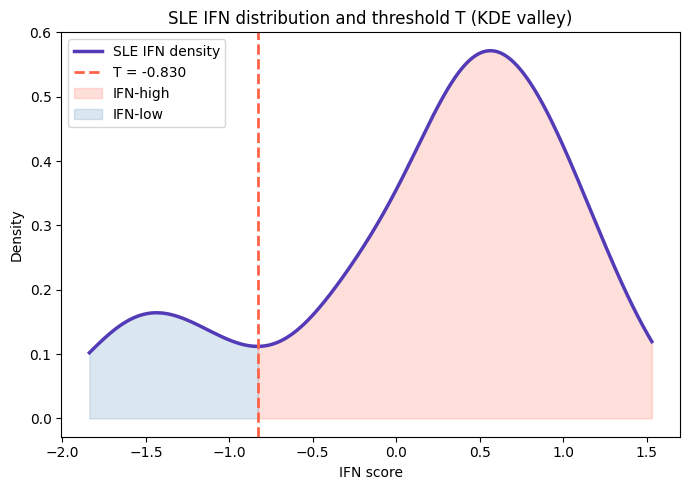

In [ ]:
kde = gaussian_kde(sle_ifn)
x_grid = np.linspace(sle_ifn.min(), sle_ifn.max(), 2000)
y_grid = kde(x_grid)

valley_idx = argrelmin(y_grid)[0]

if len(valley_idx) > 0:
    # if multiple valleys exist, take the deepest one
    T = x_grid[valley_idx[np.argmin(y_grid[valley_idx])]]
else:
    T = np.median(sle_ifn)
    print('No valley detected — falling back to median (flag this if it happens).')

sle_df['IFN_group'] = np.where(sle_df['IFN_score'] > T, 'IFN-high', 'IFN-low')

n_high = (sle_df['IFN_group']=='IFN-high').sum()
n_low  = (sle_df['IFN_group']=='IFN-low').sum()

print(f'T (KDE valley) = {T:.4f}')
print(f'IFN-high: {n_high}   IFN-low: {n_low}')

plt.figure(figsize=(7,5))
plt.plot(x_grid, y_grid, color='#533AB7', lw=2.5, label='SLE IFN density')
plt.axvline(T, color='tomato', ls='--', lw=2, label=f'T = {T:.3f}')
plt.fill_between(x_grid, y_grid, where=(x_grid > T), alpha=0.2, color='tomato', label='IFN-high')
plt.fill_between(x_grid, y_grid, where=(x_grid <= T), alpha=0.2, color='steelblue', label='IFN-low')
plt.xlabel('IFN score'); plt.ylabel('Density')
plt.title('SLE IFN distribution and threshold T (KDE valley)')
plt.legend()
plt.tight_layout()
plt.savefig('fig_threshold_T_kde.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 6b — Robustness check: is T sensitive to KDE bandwidth?

Before testing anything, check whether the KDE-valley threshold is stable across a small
set of standard, pre-named bandwidth rules — not bandwidths chosen to move T toward any
particular value. If T moves around a lot, that tells you the "natural valley" approach is
not well-determined at this sample size (n=157), which is itself an important, honest
finding — not something to paper over by picking whichever bandwidth looks best.


scott        bandwidth -> T = -0.8300
silverman    bandwidth -> T = -0.8435
fixed_0.3    bandwidth -> T = -0.7912

Range of T across bandwidths: 0.0523
-> T is STABLE across bandwidths


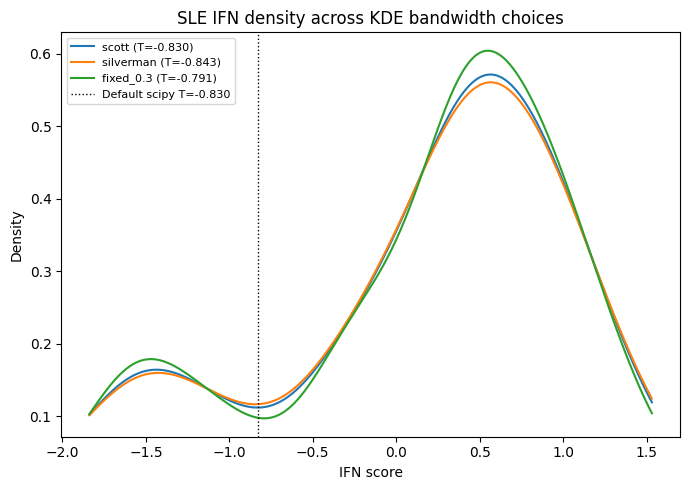

In [ ]:
bandwidth_rules = {
    'scott':     'scott',
    'silverman': 'silverman',
    'fixed_0.3': 0.3,  
}

T_by_bw = {}
for name, bw in bandwidth_rules.items():
    kde_bw = gaussian_kde(sle_ifn, bw_method=bw)
    y_bw = kde_bw(x_grid)
    valleys_bw = argrelmin(y_bw)[0]
    if len(valleys_bw) > 0:
        T_bw = x_grid[valleys_bw[np.argmin(y_bw[valleys_bw])]]
    else:
        T_bw = np.nan
    T_by_bw[name] = T_bw
    print(f'{name:12s} bandwidth -> T = {T_bw:.4f}' if not np.isnan(T_bw) else f'{name:12s} bandwidth -> no valley detected')

print()
valid_Ts = [v for v in T_by_bw.values() if not np.isnan(v)]
if len(valid_Ts) > 1:
    spread = max(valid_Ts) - min(valid_Ts)
    print(f'Range of T across bandwidths: {spread:.4f}')
    print('-> T is STABLE across bandwidths' if spread < 0.2 else '-> T is UNSTABLE -- sensitive to bandwidth choice, treat with caution')

plt.figure(figsize=(7,5))
for name, bw in bandwidth_rules.items():
    kde_bw = gaussian_kde(sle_ifn, bw_method=bw)
    plt.plot(x_grid, kde_bw(x_grid), label=f'{name} (T={T_by_bw[name]:.3f})')
plt.axvline(T, color='black', ls=':', lw=1, label=f'Default scipy T={T:.3f}')
plt.xlabel('IFN score'); plt.ylabel('Density')
plt.title('SLE IFN density across KDE bandwidth choices')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('fig_bandwidth_robustness.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 7 — SLEDAI validation of T (single pre-specified test)



=== SLEDAI validation (T = KDE valley) ===
IFN-high SLEDAI: mean=7.53  n=130
IFN-low  SLEDAI: mean=5.48  n=27
MWU p (one-sided, high > low): 0.0799


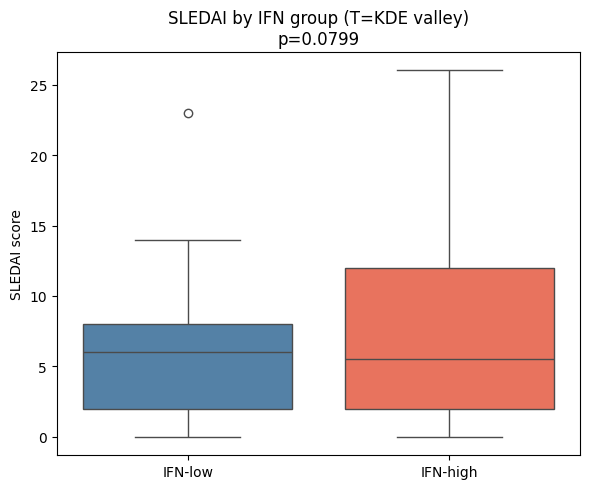

In [ ]:
high_sledai = sle_df[sle_df['IFN_group']=='IFN-high']['sledai_num'].dropna()
low_sledai  = sle_df[sle_df['IFN_group']=='IFN-low']['sledai_num'].dropna()

stat, p_sledai = mannwhitneyu(high_sledai, low_sledai, alternative='greater')

print('=== SLEDAI validation (T = KDE valley) ===')
print(f'IFN-high SLEDAI: mean={high_sledai.mean():.2f}  n={len(high_sledai)}')
print(f'IFN-low  SLEDAI: mean={low_sledai.mean():.2f}  n={len(low_sledai)}')
print(f'MWU p (one-sided, high > low): {p_sledai:.4f}')

plt.figure(figsize=(6,5))
plot_data = sle_df[['IFN_group','sledai_num']].dropna()
sns.boxplot(data=plot_data, x='IFN_group', y='sledai_num',
            order=['IFN-low','IFN-high'],
            palette={'IFN-low':'steelblue','IFN-high':'tomato'})
plt.title(f'SLEDAI by IFN group (T=KDE valley)\np={p_sledai:.4f}')
plt.xlabel(''); plt.ylabel('SLEDAI score')
plt.tight_layout()
plt.savefig('fig_sledai_kde_T.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 8 — Exploratory sensitivity check: clinically-optimized cutpoint




In [ ]:
ifn_sorted = np.sort(sle_ifn)
min_group = int(len(sle_ifn) * 0.20)
candidates = ifn_sorted[min_group:-min_group]

def best_split_diff(ifn_values, sledai_values, candidates):
    best_t, best_diff = None, -np.inf
    for t in candidates:
        high = sledai_values[ifn_values > t]
        low  = sledai_values[ifn_values <= t]
        if len(high) < 1 or len(low) < 1:
            continue
        diff = np.nanmean(high) - np.nanmean(low)
        if diff > best_diff:
            best_diff, best_t = diff, t
    return best_t, best_diff

sledai_arr = sle_df.loc[sle_df['IFN_score'].notna(), 'sledai_num'].values
ifn_arr    = sle_df.loc[sle_df['IFN_score'].notna(), 'IFN_score'].values

T_opt, observed_diff = best_split_diff(ifn_arr, sledai_arr, candidates)

high_opt = sledai_arr[ifn_arr > T_opt]
low_opt  = sledai_arr[ifn_arr <= T_opt]
high_opt = high_opt[~np.isnan(high_opt)]
low_opt  = low_opt[~np.isnan(low_opt)]
_, naive_p = mannwhitneyu(high_opt, low_opt, alternative='greater')

print(f'Optimized T = {T_opt:.4f}')
print(f'Observed max SLEDAI diff = {observed_diff:.3f}')
print(f'Naive (uncorrected) MWU p = {naive_p:.4f}  <-- this is the inflated number; do not report this alone')


n_perm = 2000
valid = ~np.isnan(sledai_arr)
ifn_valid, sledai_valid = ifn_arr[valid], sledai_arr[valid]

rng = np.random.default_rng(0)
perm_diffs = np.zeros(n_perm)
for i in range(n_perm):
    shuffled = rng.permutation(sledai_valid)
    _, d = best_split_diff(ifn_valid, shuffled, candidates)
    perm_diffs[i] = d if d is not None else -np.inf

corrected_p = (np.sum(perm_diffs >= observed_diff) + 1) / (n_perm + 1)

print(f'\nPermutation-corrected p-value (accounts for cutpoint search): {corrected_p:.4f}')
print('This is the honest p-value for the optimized-cutpoint approach.')


Optimized T = -0.0941
Observed max SLEDAI diff = 2.289
Naive (uncorrected) MWU p = 0.0170  <-- this is the inflated number; do not report this alone

Permutation-corrected p-value (accounts for cutpoint search): 0.1354
This is the honest p-value for the optimized-cutpoint approach.


## Step 9 — Sex difference within SLE (no comparison value referenced)


In [ ]:
male_sle   = sle_df[sle_df['female']==0]['IFN_score'].dropna()
female_sle = sle_df[sle_df['female']==1]['IFN_score'].dropna()

stat, p_sex = mannwhitneyu(female_sle, male_sle, alternative='two-sided')

print('=== Sex difference within SLE ===')
print(f'Male SLE   n={len(male_sle)}: mean={male_sle.mean():.4f}')
print(f'Female SLE n={len(female_sle)}: mean={female_sle.mean():.4f}')
print(f'MWU p (two-sided): {p_sex:.4f}')


=== Sex difference within SLE ===
Male SLE   n=26: mean=0.2229
Female SLE n=131: mean=0.1676
MWU p (two-sided): 0.1302


## Step 10 — Berkson's bias: build real GTEx IFN scores directly




In [ ]:
!wget -q -c https://storage.googleapis.com/adult-gtex/bulk-gex/v8/rna-seq/GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct.gz
print('GCT ready.')

from google.colab import files
uploaded = files.upload()
# Upload BOTH annotation files:
#   GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt
#   GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt


GCT ready.


Saving GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt to GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt
Saving GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt to GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt


In [ ]:
import gzip

sample_attr = pd.read_csv('GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt', sep='\t')
subj_pheno  = pd.read_csv('GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt', sep='\t')


blood_samples = set(sample_attr.loc[sample_attr['SMTSD'] == 'Whole Blood', 'SAMPID'])
print(f'Whole blood samples in annotation file: {len(blood_samples)}')

def sampid_to_subjid(sampid):
    parts = sampid.split('-')
    return '-'.join(parts[:2])

with gzip.open('GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct.gz', 'rt') as f:
    f.readline()  # version line
    f.readline()  # dims line
    header = f.readline().strip().split('\t')

blood_cols_present = [c for c in header if c in blood_samples]
print(f'Whole blood samples present in GCT file: {len(blood_cols_present)}')

usecols = ['Name', 'Description'] + blood_cols_present
gtex_expr = pd.read_csv(
    'GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct.gz',
    sep='\t', skiprows=2, usecols=usecols, compression='gzip'
)
print('Loaded GTEx whole-blood expression matrix:', gtex_expr.shape)


gtex_ifn_expr = gtex_expr[gtex_expr['Description'].isin(IFN_GENES)].set_index('Description')
gtex_ifn_expr = gtex_ifn_expr.drop(columns=['Name'])
gtex_ifn_expr = gtex_ifn_expr[~gtex_ifn_expr.index.duplicated(keep='first')]
print('ISGs found in GTEx GCT:', list(gtex_ifn_expr.index))

gtex_log = np.log2(gtex_ifn_expr.astype(float) + 1)


gtex_z_vals = gtex_log.apply(lambda row: zscore(row), axis=1, result_type='broadcast')
gtex_z = pd.DataFrame(gtex_z_vals, index=gtex_log.index, columns=gtex_log.columns)

gtex_ifn_scores = gtex_z.mean(axis=0)   
gtex_scores_df = pd.DataFrame({
    'IFN_score': gtex_ifn_scores.values
}, index=gtex_ifn_scores.index)
gtex_scores_df['SUBJID'] = gtex_scores_df.index.map(sampid_to_subjid)

# Pull sex from subject phenotypes (SEX: 1=male, 2=female in GTEx)
subj_sex = subj_pheno[['SUBJID', 'SEX']].copy()
gtex_scores_df = gtex_scores_df.merge(subj_sex, on='SUBJID', how='left')
gtex_scores_df['sex'] = gtex_scores_df['SEX'].map({1: 'male', 2: 'female'})

missing_sex = gtex_scores_df['sex'].isna().sum()
if missing_sex > 0:
    print(f'Warning: {missing_sex} samples have no matched sex label and will be dropped.')

gtex_male_ifn   = gtex_scores_df.loc[gtex_scores_df['sex']=='male',   'IFN_score'].dropna().values
gtex_female_ifn = gtex_scores_df.loc[gtex_scores_df['sex']=='female', 'IFN_score'].dropna().values

print(f'\nGTEx whole-blood IFN scores computed directly from raw data:')
print(f'  Males:   n={len(gtex_male_ifn)}   mean={gtex_male_ifn.mean():.4f}')
print(f'  Females: n={len(gtex_female_ifn)}   mean={gtex_female_ifn.mean():.4f}')
print('(Sanity check: GTEx v8 whole blood is expected to be ~507 male, ~254 female.')
print(' If these counts are far off, check the SMTSD filter and SUBJID merge above.)')

Whole blood samples in annotation file: 3288
Whole blood samples present in GCT file: 755
Loaded GTEx whole-blood expression matrix: (56200, 757)
ISGs found in GTEx GCT: ['ISG15', 'IFI6', 'IFI44L', 'IFI44', 'RSAD2', 'IFIT2', 'IFIT3', 'IFIT1', 'OAS1', 'OAS3', 'OAS2', 'OASL', 'IFI27', 'SIGLEC1', 'MX2', 'MX1', 'USP18']

GTEx whole-blood IFN scores computed directly from raw data:
  Males:   n=501   mean=-0.0437
  Females: n=254   mean=0.0861
(Sanity check: GTEx v8 whole blood is expected to be ~507 male, ~254 female.
 If these counts are far off, check the SMTSD filter and SUBJID merge above.)


=== Berkson's bias (T = KDE valley, real GTEx data) ===
T = -0.8300
GTEx males above T: 449/501 (89.6%)
Truncated GTEx male mean: 0.0786
Male SLE mean:            0.2229
Female SLE mean:          0.1676
KS test statistic: 0.4830   p = 0.0000


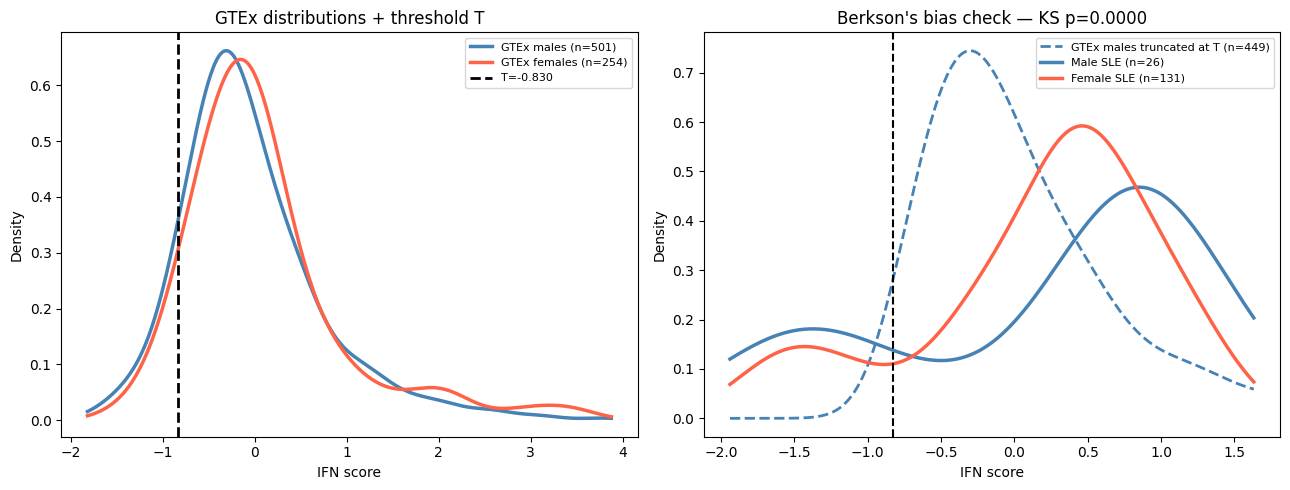

In [ ]:
male_above_T = gtex_male_ifn[gtex_male_ifn > T]
pct_above = len(male_above_T) / len(gtex_male_ifn) * 100

ks_stat, ks_p = ks_2samp(male_above_T, male_sle.values)

print('=== Berkson\'s bias (T = KDE valley, real GTEx data) ===')
print(f'T = {T:.4f}')
print(f'GTEx males above T: {len(male_above_T)}/{len(gtex_male_ifn)} ({pct_above:.1f}%)')
print(f'Truncated GTEx male mean: {male_above_T.mean():.4f}')
print(f'Male SLE mean:            {male_sle.mean():.4f}')
print(f'Female SLE mean:          {female_sle.mean():.4f}')
print(f'KS test statistic: {ks_stat:.4f}   p = {ks_p:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13,5))

ax = axes[0]
xg = np.linspace(min(gtex_male_ifn.min(), gtex_female_ifn.min())-0.1,
                  max(gtex_male_ifn.max(), gtex_female_ifn.max())+0.1, 400)
ax.plot(xg, gaussian_kde(gtex_male_ifn)(xg), 'steelblue', lw=2.5, label=f'GTEx males (n={len(gtex_male_ifn)})')
ax.plot(xg, gaussian_kde(gtex_female_ifn)(xg), 'tomato', lw=2.5, label=f'GTEx females (n={len(gtex_female_ifn)})')
ax.axvline(T, color='black', ls='--', lw=2, label=f'T={T:.3f}')
ax.set_title('GTEx distributions + threshold T')
ax.set_xlabel('IFN score'); ax.set_ylabel('Density'); ax.legend(fontsize=8)

ax = axes[1]
xs = np.linspace(sle_ifn.min()-0.1, sle_ifn.max()+0.1, 400)
if len(male_above_T) > 2:
    ax.plot(xs, gaussian_kde(male_above_T)(xs), 'steelblue', lw=2, ls='--',
            label=f'GTEx males truncated at T (n={len(male_above_T)})')
ax.plot(xs, gaussian_kde(male_sle.values)(xs), 'steelblue', lw=2.5, label=f'Male SLE (n={len(male_sle)})')
ax.plot(xs, gaussian_kde(female_sle.values)(xs), 'tomato', lw=2.5, label=f'Female SLE (n={len(female_sle)})')
ax.axvline(T, color='black', ls='--', lw=1.5)
ax.set_title(f'Berkson\'s bias check — KS p={ks_p:.4f}')
ax.set_xlabel('IFN score'); ax.set_ylabel('Density'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig_berksons_real.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 11 — TLR7 × sex interaction in SLE (ceiling effect)

In [ ]:
if 'TLR7' in expr_genes.index:
    sle_df['TLR7'] = pd.to_numeric(
        sle_df.index.map(expr_genes.loc['TLR7'].to_dict()), errors='coerce')
    df_int = sle_df[['IFN_score','TLR7','female']].dropna()
    m_int = smf.ols('IFN_score ~ TLR7 * female', data=df_int).fit()
    icoef = m_int.params.get('TLR7:female', float('nan'))
    ipval = m_int.pvalues.get('TLR7:female', float('nan'))
    print('=== TLR7 x sex interaction in SLE ===')
    print(m_int.summary().tables[1])
    print(f'\nInteraction beta = {icoef:.4f}   p = {ipval:.4f}')
else:
    print('TLR7 not found in expression matrix.')


=== TLR7 x sex interaction in SLE ===
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -7.4423      1.504     -4.950      0.000     -10.413      -4.472
TLR7            1.1255      0.220      5.125      0.000       0.692       1.559
female          5.5626      1.657      3.357      0.001       2.289       8.836
TLR7:female    -0.8190      0.243     -3.371      0.001      -1.299      -0.339

Interaction beta = -0.8190   p = 0.0009


## Final summary 


In [ ]:
print('=' * 60)
print('GSE49454 — CLEAN RESULTS SUMMARY (no target comparisons)')
print('=' * 60)
print(f'SLE patients: {len(sle_df)}   Healthy controls: {len(hc_df)}')
print()
print('-- Bimodality --')
print(f'BC = {BC:.4f}')
print()
print('-- Threshold T (KDE valley, primary) --')
print(f'T = {T:.4f}   IFN-high n={n_high}   IFN-low n={n_low}')
print(f'SLEDAI high={high_sledai.mean():.2f}  low={low_sledai.mean():.2f}  p={p_sledai:.4f}')
print()
print('-- Threshold T (optimized cutpoint, exploratory/sensitivity) --')
print(f'T_opt = {T_opt:.4f}   naive p={naive_p:.4f}   permutation-corrected p={corrected_p:.4f}')
print()
print('-- Sex difference within SLE --')
print(f'p = {p_sex:.4f}')
print()
print('-- Berkson\'s bias (real GTEx data) --')
print(f'KS p = {ks_p:.4f}   males above T = {pct_above:.1f}%')
print()
if 'icoef' in dir():
    print('-- TLR7 x sex interaction --')
    print(f'beta = {icoef:.4f}   p = {ipval:.4f}')
print('=' * 60)


GSE49454 — CLEAN RESULTS SUMMARY (no target comparisons)
SLE patients: 157   Healthy controls: 20

-- Bimodality --
BC = 0.6172

-- Threshold T (KDE valley, primary) --
T = -0.8300   IFN-high n=130   IFN-low n=27
SLEDAI high=7.53  low=5.48  p=0.0799

-- Threshold T (optimized cutpoint, exploratory/sensitivity) --
T_opt = -0.0941   naive p=0.0170   permutation-corrected p=0.1354

-- Sex difference within SLE --
p = 0.1302

-- Berkson's bias (real GTEx data) --
KS p = 0.0000   males above T = 89.6%

-- TLR7 x sex interaction --
beta = -0.8190   p = 0.0009
